In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv(r'C:\Users\HP\OneDrive\Desktop\KPMG sem3\DA using Python\test\travel-tourism-dataset.csv')

In [4]:
df.head(10)

,Trip_ID,Trip_Date,Destination,Season,Travel_Type,Transport_Mode,Trip_Duration_Days,Number_of_Travelers,Distance_km,Trip_Cost_INR,Daily_Spend_INR,Hotel_Rating,Traveler_Age,Satisfaction_Score
0,TRP0174,2025-01-01,Kerala,Monsoon,Family,Flight,4,4,1167,29882,7470.50,4.6,28,4.9
1,TRP0474,2025-01-01,Kerala,Autumn,Couple,Bus,5,1,1160,17476,3495.20,4.7,19,2.4
2,TRP0014,2025-01-01,Agra,Autumn,Business,Bus,4,5,211,6509,1627.25,5.0,31,3.2
3,TRP1181,2025-01-01,Kerala,Winter,Friends,Flight,4,2,1148,31131,7782.75,3.3,63,3.5
4,TRP0647,2025-01-02,Agra,Autumn,Couple,Train,7,3,265,12154,1736.29,4.8,21,3.7
5,TRP0828,2025-01-02,Agra,Winter,Solo,Train,9,2,398,14604,1622.67,3.0,43,3.4
6,TRP0583,2025-01-02,Goa,Summer,Family,Bus,4,5,885,13699,3424.75,3.5,21,4.9
7,TRP0883,2025-01-03,Goa,Summer,Family,Train,4,4,902,14235,3558.75,3.2,45,3.6
8,TRP0716,2025-01-03,Kerala,Summer,Business,Flight,6,2,1284,58256,9709.33,4.2,60,2.6
9,TRP0360,2025-01-03,Goa,Summer,Business,Flight,7,2,770,47873,6839.00,3.0,43,4.2


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Trip_ID              1200 non-null   object 
 1   Trip_Date            1200 non-null   object 
 2   Destination          1200 non-null   object 
 3   Season               1200 non-null   object 
 4   Travel_Type          1200 non-null   object 
 5   Transport_Mode       1200 non-null   object 
 6   Trip_Duration_Days   1200 non-null   int64  
 7   Number_of_Travelers  1200 non-null   int64  
 8   Distance_km          1200 non-null   int64  
 9   Trip_Cost_INR        1200 non-null   int64  
 10  Daily_Spend_INR      1200 non-null   float64
 11  Hotel_Rating         1200 non-null   float64
 12  Traveler_Age         1200 non-null   int64  
 13  Satisfaction_Score   1200 non-null   float64
dtypes: float64(3), int64(5), object(6)
memory usage: 131.4+ KB


In [6]:
df.isnull().sum()

Trip_ID                0
Trip_Date              0
Destination            0
Season                 0
Travel_Type            0
Transport_Mode         0
Trip_Duration_Days     0
Number_of_Travelers    0
Distance_km            0
Trip_Cost_INR          0
Daily_Spend_INR        0
Hotel_Rating           0
Traveler_Age           0
Satisfaction_Score     0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

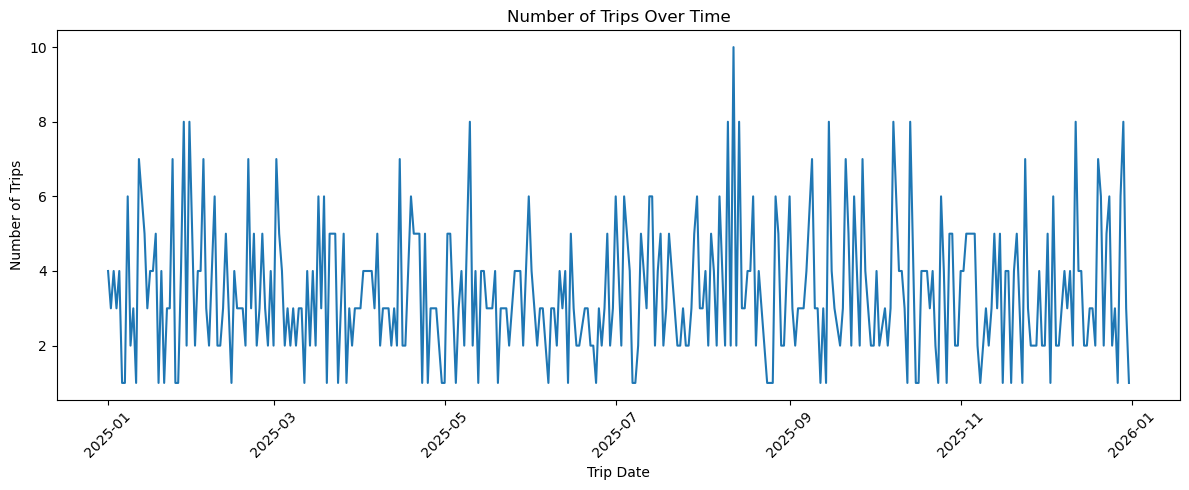

In [8]:
# line plot over no_ of trips vs numberof trip
trips_over_time = df.groupby(pd.to_datetime(df["Trip_Date"])).size().sort_index()

plt.figure(figsize=(12, 5))
plt.plot(trips_over_time.index, trips_over_time.values)
plt.title("Number of Trips Over Time")
plt.xlabel("Trip Date")
plt.ylabel("Number of Trips")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

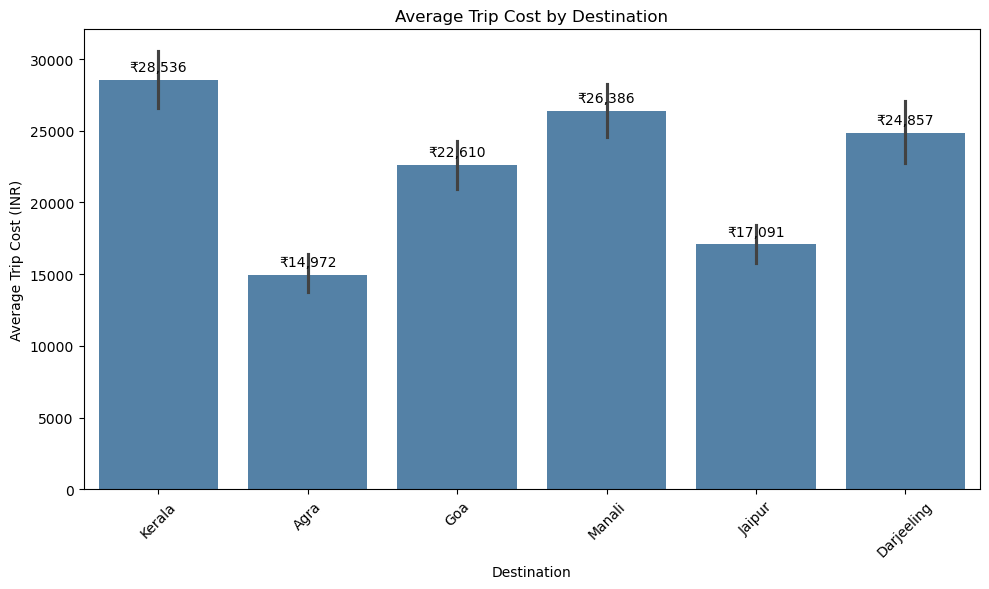

In [9]:
plt.figure(figsize=(10, 6))
ax = sns.barplot(data=df, x="Destination", y="Trip_Cost_INR", color="steelblue")

ax.set_title("Average Trip Cost by Destination")
ax.set_xlabel("Destination")
ax.set_ylabel("Average Trip Cost (INR)")
plt.xticks(rotation=45)

# Add value labels above the bars
for bar in ax.patches:
    height = bar.get_height()
    if not np.isnan(height):
        ax.annotate(
            f"₹{height:,.0f}",
            (bar.get_x() + bar.get_width() / 2, height),
            ha="center",
            va="bottom",
            xytext=(0, 4),
            textcoords="offset points"
        )

plt.tight_layout()
plt.show()

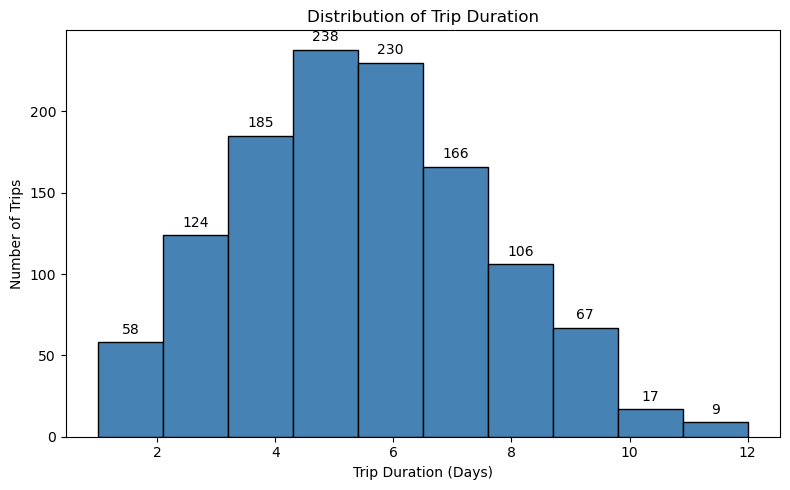

In [19]:
# . Create a histogram showing the distribution of Trip_Duration_Days
plt.figure(figsize=(8, 5))
counts, bins, patches = plt.hist(df["Trip_Duration_Days"], bins=10, color="steelblue", edgecolor="black")
for count, patch in zip(counts, patches):
    if count > 0:
        plt.annotate(
            f"{int(count)}",
            (patch.get_x() + patch.get_width() / 2, count),
            ha="center",
            va="bottom",
            xytext=(0, 4),
            textcoords="offset points",
        )
plt.title("Distribution of Trip Duration")
plt.xlabel("Trip Duration (Days)")
plt.ylabel("Number of Trips")
plt.tight_layout()
plt.show()

### 4. . Create a scatter plot showing the relationship between Distance_km and Trip_Cost_INR.

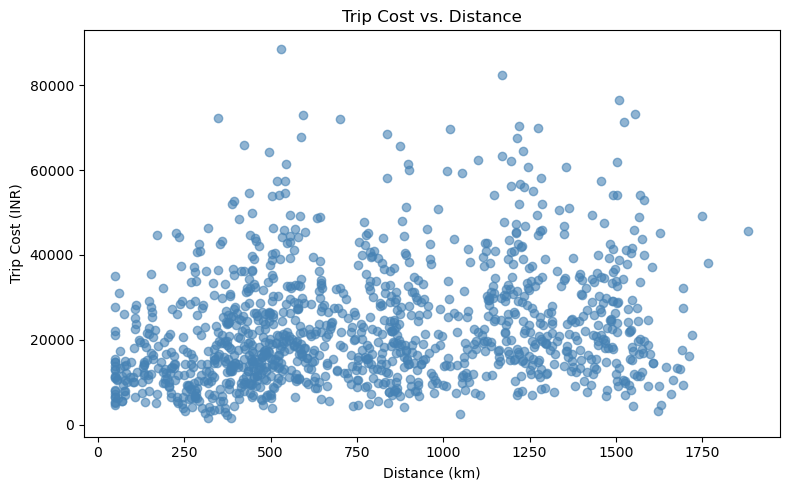

In [18]:
plt.figure(figsize=(8, 5))
plt.scatter(df["Distance_km"], df["Trip_Cost_INR"], alpha=0.6, color="steelblue")
plt.title("Trip Cost vs. Distance")
plt.xlabel("Distance (km)")
plt.ylabel("Trip Cost (INR)")
plt.tight_layout()
plt.show()

### 5. Create a box plot showing the distribution of Trip_Cost_INR for different Travel_Type categories.

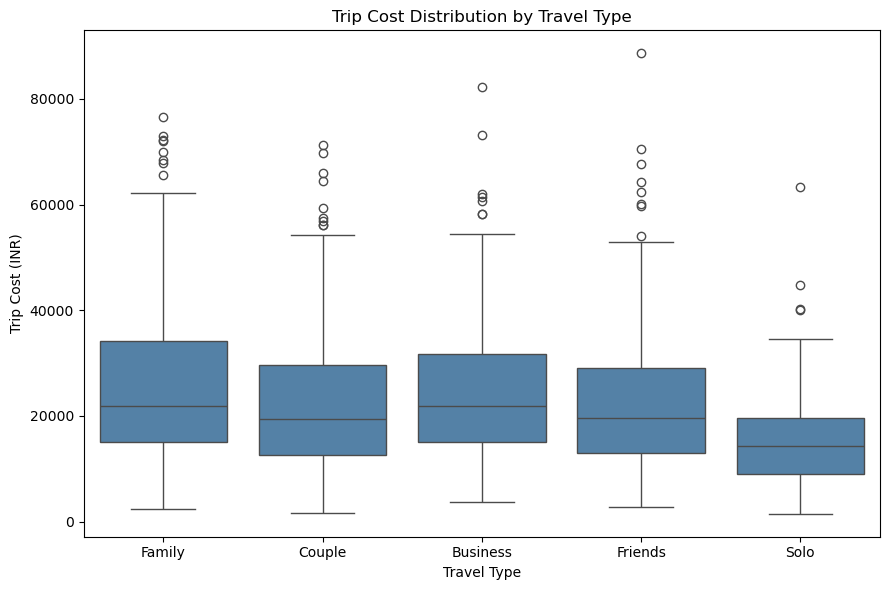

In [12]:
plt.figure(figsize=(9, 6))
sns.boxplot(data=df, x="Travel_Type", y="Trip_Cost_INR", color="steelblue")

plt.title("Trip Cost Distribution by Travel Type")
plt.xlabel("Travel Type")
plt.ylabel("Trip Cost (INR)")
plt.tight_layout()
plt.show()

### 6. Use Seaborn countplot() to display the number of trips for each Transport_Mode.

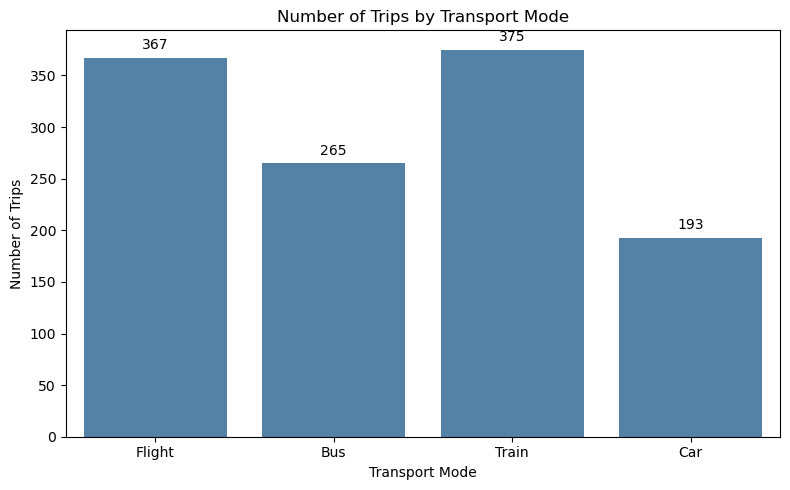

In [17]:
plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df, x="Transport_Mode", color="steelblue")

for bar in ax.patches:
    count = bar.get_height()
    ax.annotate(
        f"{int(count)}",
        (bar.get_x() + bar.get_width() / 2, count),
        ha="center",
        va="bottom",
        xytext=(0, 4),
        textcoords="offset points",
    )

plt.title("Number of Trips by Transport Mode")
plt.xlabel("Transport Mode")
plt.ylabel("Number of Trips")
plt.tight_layout()
plt.show()

### 7. Use Seaborn barplot() to compare the average Satisfaction_Score across different destinations

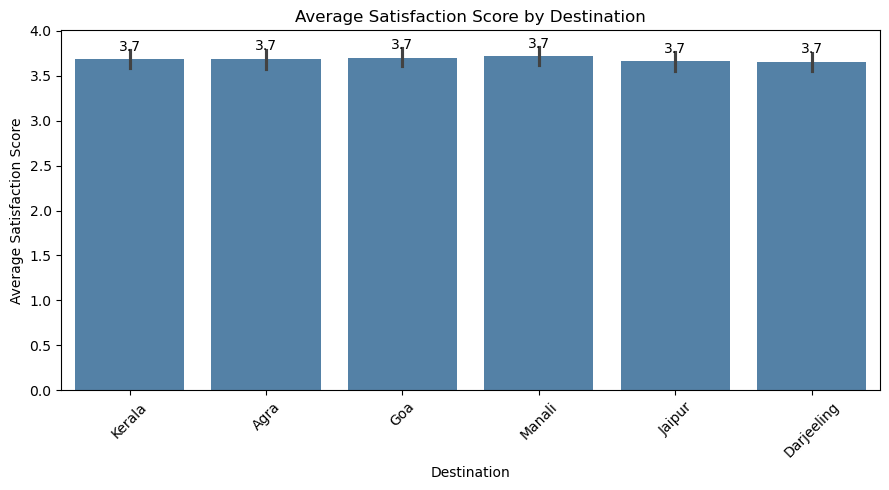

In [12]:
plt.figure(figsize=(9, 5))
ax = sns.barplot(data=df, x="Destination", y="Satisfaction_Score", color="steelblue")

for bar in ax.patches:
    height = bar.get_height()
    if not np.isnan(height):
        ax.annotate(
            f"{height:.1f}",
            (bar.get_x() + bar.get_width() / 2, height),
            ha="center",
            va="bottom",
            xytext=(0, 4),
            textcoords="offset points",
        )

plt.title("Average Satisfaction Score by Destination")
plt.xlabel("Destination")
plt.ylabel("Average Satisfaction Score")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 8. Use Seaborn histplot() to visualize the distribution of Traveler_Age.

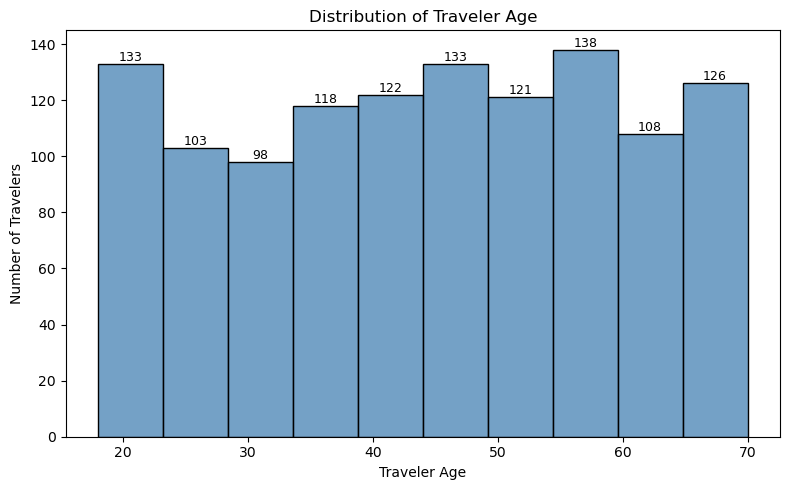

In [11]:
plt.figure(figsize=(8, 5))
ax = sns.histplot(data=df, x="Traveler_Age", bins=10, color="steelblue", edgecolor="black")

for patch in ax.patches:
    height = patch.get_height()
    if height > 0:
        ax.annotate(
            f"{int(height)}",
            (patch.get_x() + patch.get_width() / 2, height),
            ha="center",
            va="bottom",
            fontsize=9,
        )

plt.title("Distribution of Traveler Age")
plt.xlabel("Traveler Age")
plt.ylabel("Number of Travelers")
plt.tight_layout()
plt.show()

### 9. Use Seaborn boxplot() to compare Hotel_Rating across different seasons.

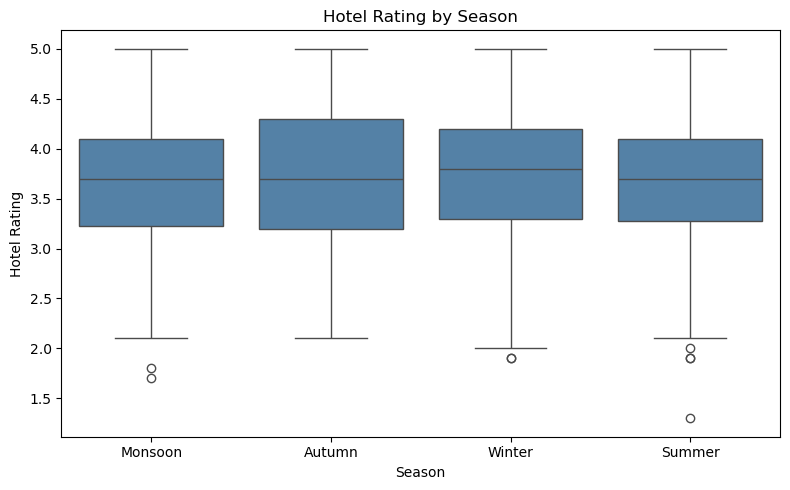

In [16]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Season", y="Hotel_Rating", color="steelblue")

plt.title("Hotel Rating by Season")
plt.xlabel("Season")
plt.ylabel("Hotel Rating")
plt.tight_layout()
plt.show()

### 10. Use Seaborn scatterplot() to visualize the relationship between Daily_Spend_INR and Trip_Duration_Days, using Travel_Type as the color (hue).

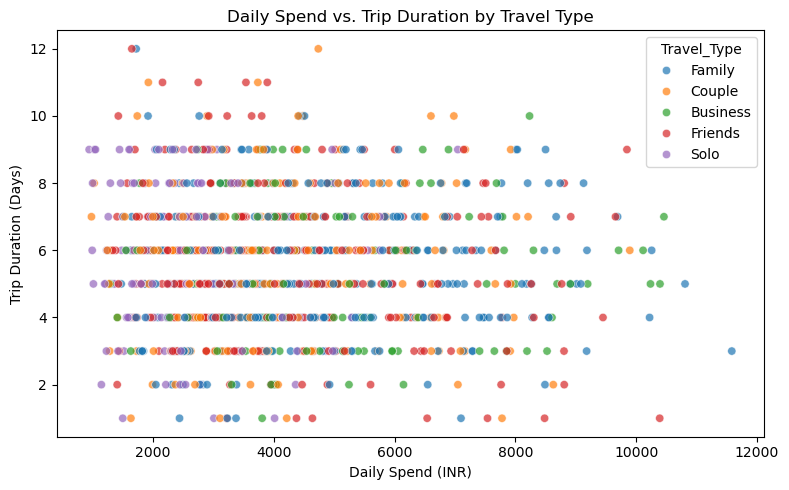

In [16]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="Daily_Spend_INR",
    y="Trip_Duration_Days",
    hue="Travel_Type",
    alpha=0.7
)

plt.title("Daily Spend vs. Trip Duration by Travel Type")
plt.xlabel("Daily Spend (INR)")
plt.ylabel("Trip Duration (Days)")
plt.tight_layout()
plt.show()